# Bipedal locomotion, part 1: reduced-order models and the capture point

A walking robot is a tower of mass balanced on a small foot. Every step is a
controlled fall: the moment a foot leaves the ground the robot is, briefly, an
inverted pendulum that *will* topple unless the next foot lands in the right
place. Planning that "right place" in real time, on an embedded processor, is
the central problem of legged locomotion.

You might hope to plan directly on the robot's full dynamics — the 30-plus
degree-of-freedom articulated body with contacts that we simulate with MJX
elsewhere in Jaxterity. You cannot, for two reasons. First, the full dynamics
are stiff, contact-rich, and non-smooth: an optimizer hates them. Second — and
decisively for *this* stack — the MJX constraint solver emits a
`lax.while_loop`, which **cannot be lowered to embedded C** (see Jaxility's
known gaps). The controller that runs on the robot's microcontroller must be
built from closed-form, smooth math.

So locomotion is planned on a **reduced-order model**: a deliberately crude,
analytically tractable surrogate that captures *just* the balance physics —
where the centre of mass is, where the contact forces push, and whether the
robot is about to fall. The whole-body controller (Part 3) then tracks that
plan with the real joints. This notebook builds the two classic reductions and
the single most useful quantity in all of bipedal balance: the **capture
point**.

**By the end of this notebook you will be able to:**

1. Write down the **single-rigid-body (centroidal) model** and verify its two
   defining properties — vertical force balance gives zero acceleration, and an
   offset force produces exactly the moment $\dot{L}=(p-c)\times f$.
2. Derive the **linear inverted pendulum (LIP)** and its **capture point**
   $\xi = c + \dot c/\omega$ from the orbital energy of the pendulum.
3. Simulate **push recovery**: hold the centre of pressure at the capture point
   and watch a shoved pendulum coast to rest on the LIP's stable manifold.
4. Ground the model in a real platform by reading the **Unitree G1**'s mass and
   CoM height with `reduced_params`.

**Reading time** ~20 min · **Runtime** ~1 min on CPU (float64, deterministic).

> **The arc (six parts).** This is Part 1 of a six-part locomotion series, each
> building on the last:
> 1. **Reduced-order models & the capture point** *(this notebook)* — the
>    surrogate physics balance is planned on.
> 2. **Centroidal MPC** — optimize contact forces over a horizon on the SRBD.
> 3. **Whole-body control** — map the centroidal plan onto the real joints.
> 4. **Gaits & footstep planning** — turn capture points into a sequence of
>    steps.
> 5. **Push recovery** — reactive stepping when a disturbance exceeds the
>    support region.
> 6. **Embedded deploy** — lower the controller to signed C with Jaxility.

> **Out of scope (here).** No whole-body dynamics, no contact scheduling, no
> optimization, no hardware. We restrict ourselves to the reduced models and
> the analytic capture-point result; everything reactive and everything
> deployed comes in later parts.


## Setup

We enable **float64** (`jax_enable_x64`) throughout — the balance quantities are
small differences of larger numbers, and we want the equilibrium checks below to
pass at machine precision, not float32 noise. Everything is deterministic; there
is no randomness in this notebook.

In [1]:
from jax import config
config.update("jax_enable_x64", True)

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

from jaxterity.locomotion.reduced import (
    srbd_dynamics, lip_omega, capture_point, lip_dynamics,
    capture_point_recovery, reduced_params, GRAVITY,
)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.grid": True,
    "grid.alpha": 0.3, "axes.axisbelow": True,
})
G = 9.81
print("float64 enabled:", jnp.zeros(1).dtype == jnp.float64)
print("gravity vector:", np.asarray(GRAVITY))

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


float64 enabled: True
gravity vector: [ 0.    0.   -9.81]


## 1. The single-rigid-body (centroidal) model

The first reduction throws away the *shape* of the robot and keeps only its
**centroidal** state: where the total mass is and how it is rotating. Collapse
every link into one rigid body and track

$$ x = \big[\,c,\ \dot c,\ L\,\big] \in \mathbb{R}^9, $$

the CoM position $c$, CoM velocity $\dot c$, and the angular momentum $L$ about
the CoM (all in the world frame). The robot touches the ground at $n_c$ contact
points $p_i$, each applying a force $f_i$. Newton and Euler, written at the CoM,
give the **single-rigid-body dynamics (SRBD)**:

$$ \ddot c = \frac{1}{m}\sum_i f_i + g, \qquad
   \dot L = \sum_i (p_i - c)\times f_i. $$

Two things make this the workhorse of locomotion planning. It is **linear in the
forces** $f_i$ — exactly the structure a convex centroidal MPC (Part 2) wants —
and it uses **only smooth operations**, so Jaxility can lower it to C. The price
is that it ignores the inertia *distribution* (swinging a leg changes $L$ in
ways a point mass can't represent); we return to that limitation under *Failure
modes*.

Let us confirm the two properties that define the model.

### 1a. Hover equilibrium — vertical force balance

If the contacts together push **straight up through the CoM** with total force
$m g$, the net force is zero and there is no moment, so the robot neither
accelerates nor starts to spin: $\ddot c = 0$ and $\dot L = 0$. This is the
trivial "standing perfectly still" solution, and it is the sanity check that our
sign conventions are right.

In [2]:
mass = 35.0                      # placeholder mass; we use the real G1 below
c = jnp.array([0.0, 0.0, 0.9])   # CoM 0.9 m up
state9 = jnp.concatenate([c, jnp.zeros(3), jnp.zeros(3)])  # at rest, no spin

# Two symmetric feet under the CoM, each carrying half the weight, pushing up.
points = jnp.array([[-0.1, 0.0, 0.0],
                    [ 0.1, 0.0, 0.0]])
forces = jnp.array([[0.0, 0.0, mass * G / 2],
                    [0.0, 0.0, mass * G / 2]])

dx = srbd_dynamics(state9, forces, points, mass=mass)
cddot_hover, Ldot_hover = dx[3:6], dx[6:9]
print("c̈ at hover :", np.asarray(cddot_hover))
print("L̇ at hover :", np.asarray(Ldot_hover))

assert float(jnp.max(jnp.abs(cddot_hover))) < 1e-9
assert float(jnp.max(jnp.abs(Ldot_hover))) < 1e-9
print("\nHover equilibrium verified: c̈ ≈ 0 and L̇ ≈ 0 (machine precision).")

c̈ at hover : [0. 0. 0.]
L̇ at hover : [0. 0. 0.]

Hover equilibrium verified: c̈ ≈ 0 and L̇ ≈ 0 (machine precision).


### 1b. An offset force makes exactly the moment $\dot L=(p-c)\times f$

Now break the balance: apply a single force with a horizontal component at a foot
*offset* from the CoM. The model must reproduce the closed-form moment
$\dot L = (p-c)\times f$ exactly — this is the term centroidal MPC uses to *steer*
angular momentum.

In [3]:
p = jnp.array([0.3, -0.2, 0.0])           # foot offset from the CoM ground track
f = jnp.array([10.0, 5.0, mass * G])      # horizontal push + weight support

dx2 = srbd_dynamics(state9, f[None, :], p[None, :], mass=mass)
cddot_off, Ldot_off = dx2[3:6], dx2[6:9]

Ldot_closed = jnp.cross(p - c, f)         # textbook moment of a force about c
cddot_closed = f / mass + GRAVITY

print("L̇  (model) :", np.asarray(Ldot_off))
print("L̇  (closed):", np.asarray(Ldot_closed))
print("c̈  (model) :", np.asarray(cddot_off))
print("c̈  (closed):", np.asarray(cddot_closed))

err_moment = float(jnp.max(jnp.abs(Ldot_off - Ldot_closed)))
err_acc    = float(jnp.max(jnp.abs(cddot_off - cddot_closed)))
print(f"\nmax |L̇ error| = {err_moment:.2e},  max |c̈ error| = {err_acc:.2e}")
assert err_moment < 1e-9 and err_acc < 1e-9
print("Offset-force moment matches the closed form to machine precision.")

L̇  (model) : [ -64.17  -112.005    3.5  ]
L̇  (closed): [ -64.17  -112.005    3.5  ]
c̈  (model) : [0.28571429 0.14285714 0.        ]
c̈  (closed): [0.28571429 0.14285714 0.        ]

max |L̇ error| = 0.00e+00,  max |c̈ error| = 0.00e+00
Offset-force moment matches the closed form to machine precision.


**Figure 1** sketches the two cases side by side: balanced vertical forces
(left, no moment) versus an offset horizontal force (right) whose lever arm
$p-c$ generates the spin-up moment we just verified.

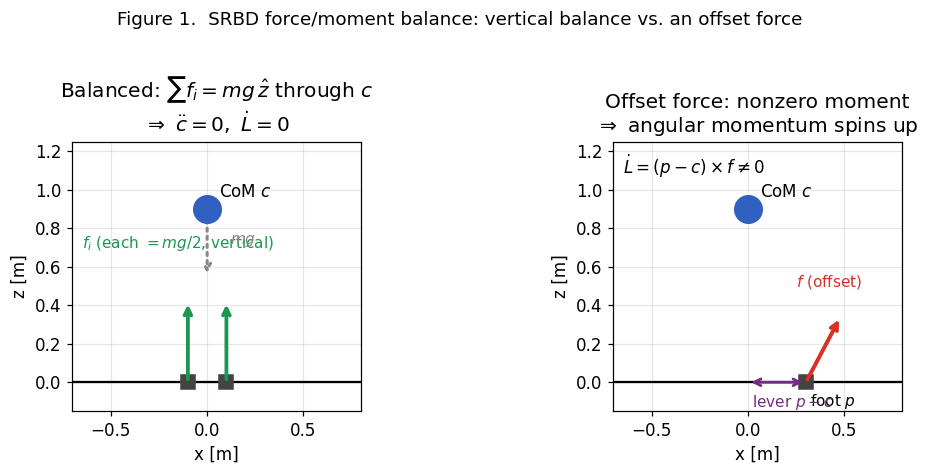

In [4]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(10, 4.2))

def draw_body(ax, cx=0.0, cz=0.9):
    ax.plot([cx], [cz], "o", ms=18, color="#3060c0", zorder=5)
    ax.annotate("CoM $c$", (cx, cz), (cx + 0.06, cz + 0.06), fontsize=11)
    ax.axhline(0, color="k", lw=1.5)
    ax.set_xlim(-0.7, 0.8); ax.set_ylim(-0.15, 1.25)
    ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("z [m]")

# Left: balanced hover
draw_body(axL)
for px in (-0.1, 0.1):
    axL.plot([px], [0], "s", ms=9, color="#444")
    axL.annotate("", xy=(px, 0.42), xytext=(px, 0.0),
                 arrowprops=dict(arrowstyle="->", color="#1a9850", lw=2.5))
axL.annotate("$f_i$ (each $=mg/2$, vertical)", (-0.1, 0.45), (-0.65, 0.7),
             fontsize=10, color="#1a9850")
axL.annotate("", xy=(0.0, 0.55), xytext=(0.0, 0.9),
             arrowprops=dict(arrowstyle="->", color="#888", lw=2, ls=":"))
axL.annotate("$mg$", (0.0, 0.7), (0.12, 0.72), color="#888", fontsize=10)
axL.set_title("Balanced: $\\sum f_i = mg\\,\\hat z$ through $c$\n$\\Rightarrow$ "
              "$\\ddot c=0,\\ \\dot L=0$")

# Right: offset force -> moment
draw_body(axR)
px2 = 0.3
axR.plot([px2], [0], "s", ms=9, color="#444")
axR.annotate("foot $p$", (px2, 0), (px2 + 0.02, -0.12), fontsize=10)
axR.annotate("", xy=(px2 + 0.18, 0.34), xytext=(px2, 0.0),
             arrowprops=dict(arrowstyle="->", color="#d73027", lw=2.6))
axR.annotate("$f$ (offset)", (px2 + 0.18, 0.34), (px2 - 0.05, 0.5),
             color="#d73027", fontsize=10)
# lever arm p - c (ground projection)
axR.annotate("", xy=(px2, 0.0), xytext=(0.0, 0.0),
             arrowprops=dict(arrowstyle="<->", color="#762a83", lw=1.8))
axR.annotate("lever $p-c$", (0.15, -0.02), (0.02, -0.13),
             color="#762a83", fontsize=10)
axR.annotate("$\\dot L=(p-c)\\times f \\ne 0$", (0.0, 1.05), (-0.65, 1.08),
             fontsize=11)
axR.set_title("Offset force: nonzero moment\n$\\Rightarrow$ angular momentum spins up")

fig.suptitle("Figure 1.  SRBD force/moment balance: vertical balance vs. an offset force",
             y=1.02, fontsize=12)
fig.tight_layout()
plt.show()

## 2. The linear inverted pendulum and the capture point

The SRBD is great for *planning forces*, but for the *balance* question — "am I
about to fall, and where must I step?" — we reduce further. Pin the CoM to a
**constant height** $h$ and ignore angular momentum entirely. What remains is a
point mass on a massless leg pivoting about the **centre of pressure (CoP)**
$p$, the point on the ground where the net ground reaction acts. In the
horizontal plane this is the **linear inverted pendulum (LIP)**:

$$ \ddot c = \omega^2\,(c - p), \qquad \omega = \sqrt{g/h}. $$

It is *linear* — that's the whole point — and unstable: the eigenvalues of the
1-D system are $\pm\omega$, one stable and one unstable mode. The unstable mode
$+\omega$ is the fall.

In [5]:
h = 0.9                      # CoM height [m] (we use the G1's real value later)
omega = float(lip_omega(h))  # ω = sqrt(g/h)
print(f"LIP height h = {h} m  ->  ω = {omega:.4f} rad/s  (period 2π/ω = {2*np.pi/omega:.3f} s)")

LIP height h = 0.9 m  ->  ω = 3.3015 rad/s  (period 2π/ω = 1.903 s)


### 2a. Deriving the capture point from orbital energy

Decouple the LIP into its two modes. Define the **orbital energy** (per unit
mass, one axis)

$$ E \;=\; \tfrac12\,\dot c^{\,2} \;-\; \tfrac12\,\omega^2\,(c-p)^2 . $$

A quick check shows $\dot E = \dot c\,\ddot c - \omega^2 (c-p)\dot c =
\dot c\,[\omega^2(c-p)] - \omega^2(c-p)\dot c = 0$: **$E$ is conserved** under
LIP dynamics. The pendulum comes to rest at the CoP ($c\to p,\ \dot c\to 0$) only
if $E = 0$. Setting $E=0$ and taking the root that *decays* toward $p$ (the
stable mode, $\dot c = -\omega(c-p)$) and solving for the CoP that achieves it
gives the **capture point**:

$$ \boxed{\ \xi \;=\; c \;+\; \dfrac{\dot c}{\omega}\ } $$

In words: **if you place the centre of pressure at $\xi$, the orbital energy is
zeroed and the CoM coasts asymptotically to rest exactly at $\xi$.** That is the
stable manifold of the LIP, and it is the single most useful fact in bipedal
balance — it tells a falling robot precisely where to put its foot. Pratt
coined the name *capture point* (2006); the underlying LIP is Kajita's (2001).

Let's compute it for a representative push.

In [6]:
c0    = jnp.array([0.0, 0.0])     # start at the origin, in the support
cdot0 = jnp.array([0.4, -0.2])    # shoved: 0.4 m/s forward, 0.2 m/s sideways
xi0   = capture_point(c0, cdot0, omega)
print("initial CoM      c0   =", np.asarray(c0))
print("push velocity    ċ0   =", np.asarray(cdot0), "m/s")
print("capture point    ξ0   =", np.asarray(xi0), "m   (= c0 + ċ0/ω)")
print(f"capture distance |ξ0| = {float(jnp.linalg.norm(xi0)):.4f} m from current CoM")

initial CoM      c0   = [0. 0.]
push velocity    ċ0   = [ 0.4 -0.2] m/s
capture point    ξ0   = [ 0.12115651 -0.06057825] m   (= c0 + ċ0/ω)


capture distance |ξ0| = 0.1355 m from current CoM


## 3. Push recovery: coasting to rest on the stable manifold

Now the payoff. We hold the CoP **fixed at the capture point** $\xi_0$ computed
from the push, and integrate the LIP forward. The theory says the CoM should
decelerate and settle exactly at $\xi_0$ with zero velocity — no oscillation, no
overshoot, because we put the state precisely on the stable manifold. (In a real
robot you'd *step* the foot to $\xi_0$; here we just move the CoP, which is the
continuous idealization.)

`capture_point_recovery` integrates `lip_dynamics` with the CoP pinned at
$\xi_0$ and returns the time series.

In [7]:
dt, n_steps = 0.002, 3000
t, cs, cds = capture_point_recovery(c0, cdot0, omega, dt=dt, n_steps=n_steps)
t  = np.asarray(t)
cs = np.asarray(cs)     # CoM track (N, 2)
cds = np.asarray(cds)   # CoM velocity (N, 2)

c_end, cdot_end = cs[-1], cds[-1]
print(f"final CoM      c_end   = {c_end}")
print(f"target (ξ0)             = {np.asarray(xi0)}")
print(f"final velocity ċ_end   = {cdot_end}   (|ċ_end| = {np.linalg.norm(cdot_end):.3e} m/s)")

assert np.linalg.norm(cdot_end) < 1e-2,         "CoM did not come to rest"
assert np.allclose(c_end, np.asarray(xi0), atol=1e-2), "CoM did not settle at ξ0"
print("\nRecovery verified: |ċ_end| < 1e-2 and c_end ≈ ξ0 (atol 1e-2).")

# Orbital energy is conserved at ~0 along the whole trajectory.
p_cop = np.asarray(xi0)
E = 0.5*np.sum(cds**2, axis=1) - 0.5*omega**2*np.sum((cs - p_cop)**2, axis=1)
print(f"max |orbital energy| over trajectory = {np.max(np.abs(E)):.2e}  (≈ 0 ⇒ on stable manifold)")

final CoM      c_end   = [ 0.12115651 -0.06057826]
target (ξ0)             = [ 0.12115651 -0.06057825]
final velocity ċ_end   = [ 2.3367936e-08 -1.1683968e-08]   (|ċ_end| = 2.613e-08 m/s)

Recovery verified: |ċ_end| < 1e-2 and c_end ≈ ξ0 (atol 1e-2).
max |orbital energy| over trajectory = 8.50e-17  (≈ 0 ⇒ on stable manifold)


**Figure 2** shows the recovery two ways. *Left:* the phase portrait
($c$ vs $\dot c$) for the x-axis, with the LIP's stable ($\dot c=-\omega(c-p)$)
and unstable ($\dot c=+\omega(c-p)$) eigenlines through the CoP. The trajectory
starts off-axis (the push) and slides **down the stable eigenline** into the
fixed point at $(\xi_0,0)$ — it never touches the unstable manifold, which is
why it doesn't fall. *Right:* the time series — position rising smoothly to
$\xi_0$ and velocity decaying monotonically to zero.

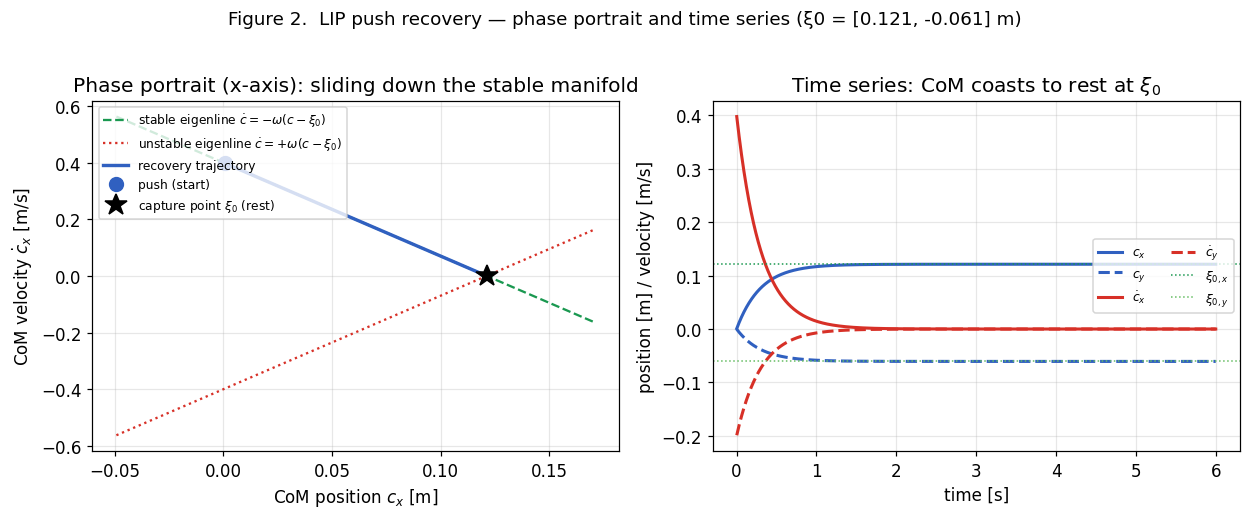

In [8]:
fig, (axP, axT) = plt.subplots(1, 2, figsize=(11.5, 4.6))

# --- Phase portrait (x-axis) ---
xi_x = float(xi0[0])
cx_line = np.linspace(min(cs[:,0].min(), xi_x) - 0.05, xi_x + 0.05, 50)
axP.plot(cx_line,  -omega*(cx_line - xi_x), "--", color="#1a9850", lw=1.5,
         label="stable eigenline $\\dot c=-\\omega(c-\\xi_0)$")
axP.plot(cx_line,  +omega*(cx_line - xi_x), ":", color="#d73027", lw=1.5,
         label="unstable eigenline $\\dot c=+\\omega(c-\\xi_0)$")
axP.plot(cs[:,0], cds[:,0], "-", color="#3060c0", lw=2.2, label="recovery trajectory")
axP.plot(cs[0,0], cds[0,0], "o", color="#3060c0", ms=9, label="push (start)")
axP.plot(xi_x, 0.0, "*", color="k", ms=15, label="capture point $\\xi_0$ (rest)")
axP.set_xlabel("CoM position $c_x$ [m]")
axP.set_ylabel("CoM velocity $\\dot c_x$ [m/s]")
axP.set_title("Phase portrait (x-axis): sliding down the stable manifold")
axP.legend(fontsize=8, loc="upper left")

# --- Time series ---
axT.plot(t, cs[:,0],  color="#3060c0", lw=2, label="$c_x$")
axT.plot(t, cs[:,1],  color="#3060c0", lw=2, ls="--", label="$c_y$")
axT.plot(t, cds[:,0], color="#d73027", lw=2, label="$\\dot c_x$")
axT.plot(t, cds[:,1], color="#d73027", lw=2, ls="--", label="$\\dot c_y$")
axT.axhline(xi_x, color="#1a9850", lw=1, ls=":", label="$\\xi_{0,x}$")
axT.axhline(float(xi0[1]), color="#66bd63", lw=1, ls=":", label="$\\xi_{0,y}$")
axT.set_xlabel("time [s]"); axT.set_ylabel("position [m] / velocity [m/s]")
axT.set_title("Time series: CoM coasts to rest at $\\xi_0$")
axT.legend(fontsize=8, ncol=2, loc="center right")

fig.suptitle("Figure 2.  LIP push recovery — phase portrait and time series "
             f"(ξ0 = [{float(xi0[0]):.3f}, {float(xi0[1]):.3f}] m)",
             y=1.02, fontsize=12)
fig.tight_layout()
plt.show()

### 3a. The capture point, geometrically

**Figure 3** is the one-picture summary of the whole notebook. The capture point
is the current CoM *plus the velocity scaled by* $1/\omega$ — a fast push
($\dot c$ large) or a tall, slow pendulum ($\omega$ small, $h$ large) throws the
capture point farther out. If $\xi$ lands **inside the support polygon** (the
foot), the robot can recover *in place* by shifting its CoP. If $\xi$ falls
**outside** it, no admissible CoP can catch the fall and the robot **must take a
step** to a new support that contains $\xi$ — the seed of Part 5.

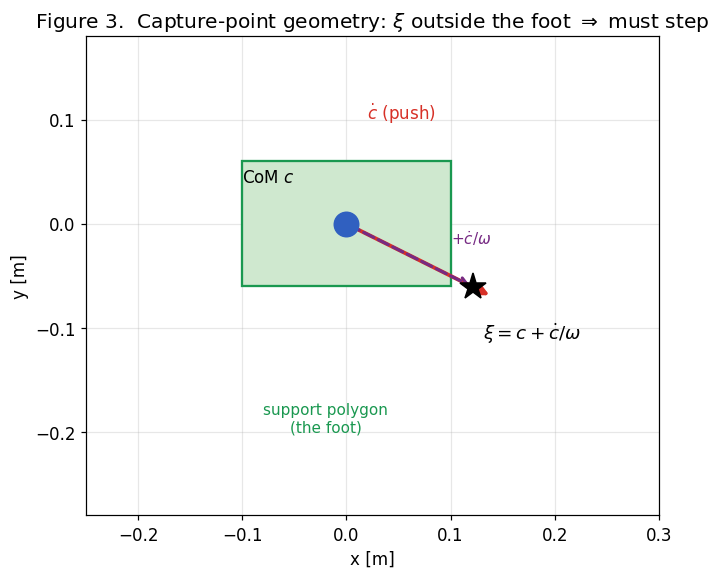

ξ0 = [ 0.12115651 -0.06057825] m;  foot half-extents ±[0.10, 0.06] m
ξ0 lies OUTSIDE the support polygon -> this push requires a step.


In [9]:
fig, ax = plt.subplots(figsize=(7.2, 5.4))

# A schematic foot / support polygon at the origin.
foot = plt.Rectangle((-0.10, -0.06), 0.20, 0.12, fill=True,
                     color="#cfe8cf", ec="#1a9850", lw=1.5, zorder=1)
ax.add_patch(foot)
ax.annotate("support polygon\n(the foot)", (0.0, -0.06), (-0.02, -0.20),
            ha="center", fontsize=10, color="#1a9850")

cx, cy = float(c0[0]), float(c0[1])
ax.plot(cx, cy, "o", ms=16, color="#3060c0", zorder=5)
ax.annotate("CoM $c$", (cx, cy), (cx - 0.10, cy + 0.04), fontsize=11)

# velocity arrow
vscale = 0.35
ax.annotate("", xy=(cx + vscale*float(cdot0[0]), cy + vscale*float(cdot0[1])),
            xytext=(cx, cy),
            arrowprops=dict(arrowstyle="->", color="#d73027", lw=2.5))
ax.annotate("$\\dot c$ (push)", (cx + vscale*float(cdot0[0]),
            cy + vscale*float(cdot0[1])), (cx + 0.02, cy + 0.10),
            color="#d73027", fontsize=11)

# capture-point offset = cdot / omega
ax.annotate("", xy=(float(xi0[0]), float(xi0[1])), xytext=(cx, cy),
            arrowprops=dict(arrowstyle="->", color="#762a83", lw=2.0, ls="--"))
ax.plot(float(xi0[0]), float(xi0[1]), "*", color="k", ms=18, zorder=6)
ax.annotate("$\\xi = c + \\dot c/\\omega$", (float(xi0[0]), float(xi0[1])),
            (float(xi0[0]) + 0.01, float(xi0[1]) - 0.05), fontsize=12)

ax.annotate("$+\\dot c/\\omega$", (0.5*(cx+float(xi0[0])), 0.5*(cy+float(xi0[1]))),
            (0.10, -0.02), color="#762a83", fontsize=10)

ax.set_xlim(-0.25, 0.30); ax.set_ylim(-0.28, 0.18)
ax.set_aspect("equal")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Figure 3.  Capture-point geometry: $\\xi$ outside the foot $\\Rightarrow$ must step")
fig.tight_layout()
plt.show()

print(f"ξ0 = {np.asarray(xi0)} m;  foot half-extents ±[0.10, 0.06] m")
print("ξ0 lies OUTSIDE the support polygon -> this push requires a step.")

### 3b. Recovery for several push magnitudes

Sweeping the push magnitude (same direction) shows the family of recoveries:
each coasts to its own capture point, and the capture distance grows **linearly**
with push speed (since $\xi - c = \dot c/\omega$). **Figure 4** overlays the
phase trajectories and confirms the linear relationship.

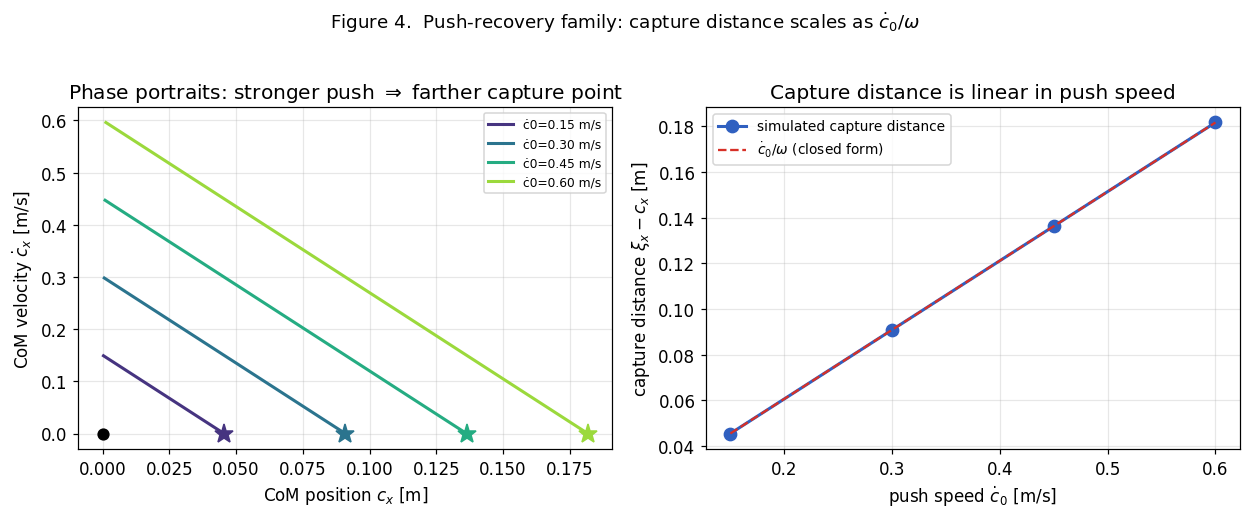

capture distances: ['0.0454', '0.0909', '0.1363', '0.1817']
closed form ċ0/ω : ['0.0454', '0.0909', '0.1363', '0.1817']


In [10]:
pushes = [0.15, 0.30, 0.45, 0.60]   # forward push speeds [m/s]
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(pushes)))

fig, (axP, axB) = plt.subplots(1, 2, figsize=(11.5, 4.6))
cap_dist = []
for v, col in zip(pushes, colors):
    cd0 = jnp.array([v, 0.0])
    xi  = capture_point(c0, cd0, omega)
    cap_dist.append(float(xi[0]))
    _, cc, ccd = capture_point_recovery(c0, cd0, omega, dt=dt, n_steps=n_steps)
    cc, ccd = np.asarray(cc), np.asarray(ccd)
    axP.plot(cc[:,0], ccd[:,0], color=col, lw=2, label=f"ċ0={v:.2f} m/s")
    axP.plot(float(xi[0]), 0.0, "*", color=col, ms=13)
    # final state assertion
    assert np.linalg.norm(ccd[-1]) < 1e-2
    assert abs(cc[-1,0] - float(xi[0])) < 1e-2

axP.plot(0, 0, "ko", ms=7)
axP.set_xlabel("CoM position $c_x$ [m]")
axP.set_ylabel("CoM velocity $\\dot c_x$ [m/s]")
axP.set_title("Phase portraits: stronger push $\\Rightarrow$ farther capture point")
axP.legend(fontsize=8)

axB.plot(pushes, cap_dist, "o-", color="#3060c0", lw=2, ms=8,
         label="simulated capture distance")
xx = np.array(pushes)
axB.plot(xx, xx/omega, "--", color="#d73027", lw=1.5,
         label="$\\dot c_0/\\omega$ (closed form)")
axB.set_xlabel("push speed $\\dot c_0$ [m/s]")
axB.set_ylabel("capture distance $\\xi_x - c_x$ [m]")
axB.set_title("Capture distance is linear in push speed")
axB.legend(fontsize=9)

fig.suptitle("Figure 4.  Push-recovery family: capture distance scales as $\\dot c_0/\\omega$",
             y=1.02, fontsize=12)
fig.tight_layout()
plt.show()
print("capture distances:", [f"{d:.4f}" for d in cap_dist])
print("closed form ċ0/ω :", [f"{v/omega:.4f}" for v in pushes])

## 4. Grounding the model in a real robot: the Unitree G1

A reduced model is only useful if its two parameters — total **mass** $m$ and
nominal **CoM height** $h$ — come from the real platform. `reduced_params` loads
the robot, sums the body masses, and computes the whole-body CoM height at the
home posture. Here is the **Unitree G1** humanoid.

In [11]:
from jaxterity import zoo

robot = zoo.unitree_g1.load(floating_base=True)
rp = reduced_params(robot)
m_g1, h_g1 = rp["mass"], rp["com_height"]
omega_g1 = float(lip_omega(h_g1))

print(f"Unitree G1 — reduced-model parameters")
print(f"  total mass m   = {m_g1:.3f} kg")
print(f"  CoM height  h   = {h_g1:.3f} m")
print(f"  LIP frequency ω = √(g/h) = {omega_g1:.4f} rad/s")
print(f"  characteristic time 1/ω = {1/omega_g1:.3f} s")

assert 20.0 < m_g1 < 80.0,   f"G1 mass out of range: {m_g1}"
assert 0.3  < h_g1 < 1.2,    f"G1 com_height out of range: {h_g1}"
print("\nG1 parameters in expected range (mass 20–80 kg, height 0.3–1.2 m).")

Unitree G1 — reduced-model parameters
  total mass m   = 33.341 kg
  CoM height  h   = 0.685 m
  LIP frequency ω = √(g/h) = 3.7854 rad/s
  characteristic time 1/ω = 0.264 s

G1 parameters in expected range (mass 20–80 kg, height 0.3–1.2 m).


With the G1's real $\omega$, the capture point for a given push is now a
concrete number for *this* robot. A 0.4 m/s shove on the G1: 

In [12]:
xi_g1 = capture_point(jnp.array([0.0, 0.0]), jnp.array([0.4, 0.0]), omega_g1)
print(f"G1, ċ0 = 0.4 m/s forward  ->  capture point ξ = {np.asarray(xi_g1)} m")
print(f"  i.e. the G1 must place its foot {float(xi_g1[0]):.3f} m ahead to catch this push.")

G1, ċ0 = 0.4 m/s forward  ->  capture point ξ = [0.10566987 0.        ] m
  i.e. the G1 must place its foot 0.106 m ahead to catch this push.


## Failure modes

Reduced models earn their tractability by *lying* about the robot, and you have
to know where the lies bite.

- **Capture point outside the support → you cannot recover in place.** The whole
  derivation assumes you can put the CoP at $\xi$. The CoP is physically confined
  to the support polygon (you can't push on ground you aren't standing on). When
  $\xi$ leaves the foot — Figure 3 — no admissible CoP zeroes the orbital energy
  and the robot **must step**. Treating $\xi$ as always reachable is the classic
  way to make a balance controller confidently fall over.
- **The LIP ignores angular momentum.** Collapsing to a point mass discards $L$
  entirely, yet humans (and good robots) recover from big pushes partly by
  *windmilling* — pumping angular momentum to buy time. The LIP can't see that
  strategy; for those regimes you need the SRBD's $\dot L$ term, or the full WBC.
- **Constant-height assumption.** The LIP pins $c_z = h$. Crouching, stairs, or
  vertical CoM excursions violate this; the linearization degrades and $\omega$
  is no longer constant. The SRBD has no such restriction (it's the more honest
  of the two), which is why Part 2 plans forces on the SRBD, not the LIP.
- **No contact constraints or friction.** Neither model knows that forces must
  be unilateral (push, not pull) and inside the friction cone. The MPC of Part 2
  adds those as inequality constraints; the bare dynamics here will happily
  return physically impossible forces if you ask.


## Exercises

- **Easy.** Re-run Section 3 with a *sideways* push `cdot0 = [0.0, 0.3]`.
  Confirm $\xi_0$ moves purely along $y$ and the recovery still settles with
  $|\dot c_{\text{end}}| < 10^{-2}$.
- **Medium.** The capture distance is $\dot c_0/\omega$, so a taller robot
  (larger $h$, smaller $\omega$) has a *farther* capture point for the same push.
  Plot capture distance vs. CoM height $h\in[0.5,1.1]$ m at a fixed push speed
  and explain the trend physically.
- **Hard.** Add a constant disturbance force to `lip_dynamics` (a steady wind):
  $\ddot c = \omega^2(c-p) + a_{\text{dist}}$. Derive the new fixed point and the
  *offset* capture point that holds the CoM at rest, and verify it numerically.
- **Open.** The LIP throws away $L$. Using `srbd_dynamics`, design a recovery
  that uses an angular-momentum ("windmill") moment $\dot L$ to buy time before
  stepping, and quantify how much farther a push it can survive than the bare
  capture-point step. (This is genuinely a research question — it is the
  *capturability* literature.)


## References

- S. Kajita et al., *The 3D Linear Inverted Pendulum Mode: A simple modeling for
  a biped walking pattern generation*, IROS 2001. — the LIP model.
- J. Pratt, J. Carff, S. Drakunov, A. Goswami, *Capture Point: A Step toward
  Humanoid Push Recovery*, Humanoids 2006. — defines the capture point and the
  push-recovery result reproduced here.
- D. E. Orin, A. Goswami, S.-H. Lee, *Centroidal dynamics of a humanoid robot*,
  Autonomous Robots 35(2–3), 2013. — the single-rigid-body / centroidal model of
  Section 1.


## Next steps

You now have the two reductions locomotion is planned on, and the capture point
that turns "I'm falling" into "step here." **Part 2: Centroidal MPC** keeps the
SRBD of Section 1 and optimizes the contact forces $f_i$ over a horizon — the
linear-in-forces structure we verified is exactly what makes that optimization
convex and, ultimately, deployable to embedded C with Jaxility. See you there.
